# Prédire la consommation de data d'un client à partir de son forfait

**Objectif :** estimer la consommation de data mensuelle (en Go) d'un client d'opérateur télécom à partir du prix de son forfait, avec une **régression linéaire simple**, puis analyser les limites du modèle.

**Données :** `clients.csv`, un fichier de clients avec leur ancienneté, leur forfait, leur consommation de data, leurs appels au support, leurs retards de paiement et s'ils ont résilié. Ici, on utilise uniquement `forfait` (variable explicative) et `conso_data` (variable cible).

**Démarche :**
1. Chargement des données
2. Visualisation de la relation entre forfait et consommation
3. Baseline : prédire la moyenne pour tout le monde
4. Entraînement de la régression linéaire et interprétation des coefficients
5. Évaluation sur un jeu de test (RMSE et R²)
6. Analyse des limites du modèle

## Imports

In [1]:
import pandas as pd 
import matplotlib.pyplot as plt
from sklearn.metrics import mean_squared_error
from sklearn.linear_model import LinearRegression
from sklearn.metrics import r2_score
from sklearn.model_selection import train_test_split

## 1. Chargement des données

In [2]:
df = pd.read_csv('clients.csv')
print(df.head())

  client_id  anciennete  forfait  conso_data  appels_support  retards  \
0    C10000          24    18.96         3.9               0        0   
1    C10001          50    19.49         1.3               2        1   
2    C10002          33    24.26         0.7               0        0   
3    C10003          54    40.92        13.9               1        0   
4    C10004           8    40.48        22.1               3        1   

  a_resilie  
0       non  
1       non  
2       non  
3       non  
4       non  


## 2. Visualisation de la relation

Avant de modéliser, on vérifie avec un nuage de points que le forfait et la consommation sont liés, et que ce lien ressemble à une droite.

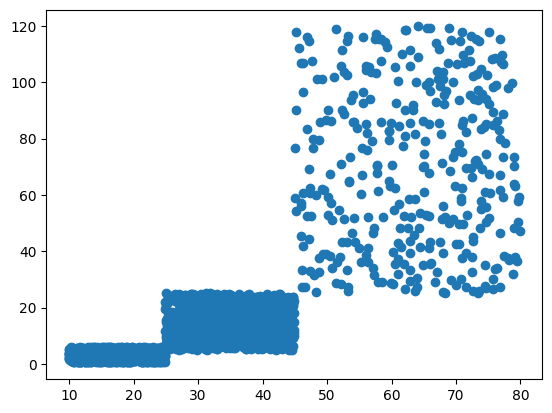

In [3]:
x = df[["forfait"]]
y = df["conso_data"]
plt.scatter(x, y)

**Constat :** le nuage monte de gauche à droite : plus le forfait est cher, plus la consommation est élevée. Le lien est réel, mais le nuage **s'élargit** quand le forfait augmente : les clients aux forfaits élevés ont des consommations beaucoup plus dispersées.

## 3. Baseline : prédire la moyenne

On compare le modèle à une stratégie naïve : prédire la consommation moyenne pour tous les clients. Le **RMSE** mesure l'erreur typique de prédiction, en Go.

In [4]:
y_moyenne = [y.mean()] * len(y) 
rmse_moyenne = round(mean_squared_error(y, y_moyenne) ** 0.5, 2)
print("RMSE pour la moyenne : ", rmse_moyenne)

RMSE pour la moyenne :  27.02


**Résultat :** en prédisant la moyenne, on se trompe en moyenne d'environ **27 Go**. C'est le score à battre.

## 4. Régression linéaire

On entraîne le modèle sur l'ensemble des données pour obtenir l'équation de la droite.

In [5]:
model = LinearRegression()
model.fit(x, y)
y_pred = model.predict(x)
print("Coefficient de régression : ", model.coef_[0])
print("Ordonnée à l'origine : ", model.intercept_)

Coefficient de régression :  1.2313680216762126
Ordonnée à l'origine :  -20.23921235419556


**Équation obtenue :** `conso_data ≈ 1,23 × forfait − 20,24`

- **Coefficient (≈ 1,23)** : chaque euro de forfait supplémentaire correspond à environ 1,23 Go de consommation en plus.
- **Ordonnée à l'origine (≈ −20,24)** : cette valeur n'a pas de sens concret. D'après la droite, un client dont le forfait est inférieur à environ 16,4 € aurait une consommation **négative**, ce qui est impossible. C'est un premier signe que la relation n'est pas parfaitement linéaire.

### Droite de régression

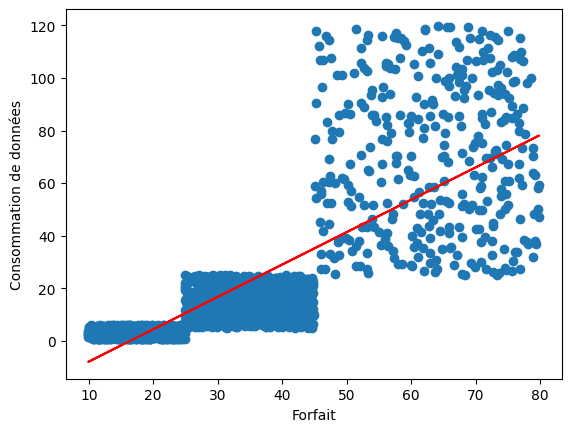

In [6]:
plt.scatter(x,y)
plt.plot(x, y_pred, color='red')
plt.xlabel("Forfait")
plt.ylabel("Consommation de données")
plt.show()

**Constat :** la droite suit la tendance générale, mais beaucoup de points en sont éloignés, surtout pour les forfaits élevés.

### Performance du modèle

In [7]:
rmse_modele  = round(mean_squared_error(y, y_pred) ** 0.5, 2)
R2 = r2_score(y, y_pred)
print("RMSE pour le modèle : ", rmse_modele)
print("RMSE pour la moyenne : ", rmse_moyenne)
print("R² pour le modèle : ", R2)


RMSE pour le modèle :  16.34
RMSE pour la moyenne :  27.02
R² pour le modèle :  0.6343879470681298


**Résultat :** le RMSE passe de 27,02 (baseline) à **16,34 Go**, soit environ **40 % d'erreur en moins**. Le R² de **0,63** indique que le forfait explique environ 63 % des variations de consommation.

Le modèle est donc meilleur que la moyenne, mais une erreur typique de 16 Go reste importante pour une consommation de quelques dizaines de Go.

### Prédiction pour un nouveau client

Consommation estimée pour un client ayant un forfait à 45 €.

In [8]:
client = pd.DataFrame({"forfait": [45]})
print(model.predict(client))

[35.17234862]


**Résultat :** un client à 45 € consommerait environ **35 Go**. Compte tenu du RMSE, cette estimation reste approximative.

## 5. Évaluation sur un jeu de test

On sépare les données : 70 % pour l'entraînement et 30 % pour le test, afin de mesurer la performance sur des clients que le modèle n'a jamais vus.

In [9]:
x_train, x_test, y_train, y_test = train_test_split(x, y, test_size=0.3, random_state=42)
model_train = LinearRegression()
model_train.fit(x_train, y_train)
y_pred_train = model_train.predict(x_train)
rmse_train = round(mean_squared_error(y_train, y_pred_train) ** 0.5, 2)
r2_train = r2_score(y_train, y_pred_train)
print("RMSE pour le modèle sur l'ensemble d'entraînement : ", rmse_train)   
print("R² pour le modèle sur l'ensemble d'entraînement : ", r2_train)

RMSE pour le modèle sur l'ensemble d'entraînement :  15.73
R² pour le modèle sur l'ensemble d'entraînement :  0.6211485149185648


In [10]:
y_pred_te = model_train.predict(x_test)
rmse_te = mean_squared_error(y_test, y_pred_te) ** 0.5
r2_te = r2_score(y_test, y_pred_te)

print("Apprentissage : RMSE =", round(rmse_train, 2), "| R² =", round(r2_train, 3))
print("Test          : RMSE =", round(rmse_te, 2), "| R² =", round(r2_te, 3))

Apprentissage : RMSE = 15.73 | R² = 0.621
Test          : RMSE = 17.78 | R² = 0.65


### Comparaison entraînement / test

| Jeu | RMSE | R² |
|---|---|---|
| Entraînement | 15,73 | 0,62 |
| Test | 17,78 | 0,65 |

**Interprétation :** les scores sont proches sur l'entraînement et le test, donc le modèle ne fait **pas de surapprentissage** : il se comporte de la même façon sur des clients jamais vus. Le R² légèrement meilleur sur le test vient du hasard du découpage.

## 6. Conclusion et limites

- Il existe un **lien positif clair** entre le prix du forfait et la consommation de data.
- La régression linéaire réduit l'erreur d'environ 40 % par rapport à la baseline et généralise bien (R² de 0,65 sur le test).
- Le modèle reste cependant **peu précis** : une erreur typique de 16 à 18 Go limite son utilité pour des prédictions individuelles.

**Pourquoi le modèle est limité :**
- **Ordonnée à l'origine négative** : le modèle peut prédire des consommations impossibles pour les petits forfaits.
- **Dispersion croissante** : l'erreur augmente avec le prix du forfait, alors que la régression linéaire suppose une erreur à peu près constante.
- **Une seule variable** : le forfait ne suffit pas à expliquer la consommation.

**Pistes d'amélioration :**
- Tracer le **graphique des résidus** pour confirmer la dispersion croissante.
- Prédire `log(1 + conso_data)` plutôt que `conso_data` pour réduire l'effet de cette dispersion.
- Passer à une **régression linéaire multiple** en ajoutant `anciennete`, `appels_support` et `retards`.